# 단계적 공개와 설계 비교

**이 노트북에서 할 일**

1. 문서 세 개의 목록을 먼저 보고, 질문에 필요한 문서 하나의 본문만 엽니다.
2. 전체 입력·고른 입력·줄인 입력을 같은 질문으로 보내고, 토큰 수와 비용을 기록합니다.
3. Ch 7 08절 기록 파일의 지문을 출처로 적어, 세 기록을 기록 파일로 남깁니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. Ch 7 08절 노트북도 먼저 실행해 둡니다.
그 노트북이 만든 기록 파일 `prompt-ab-continuity.json`을 이 노트북이 읽기 때문입니다.

인터넷 서비스에 요청을 모두 5번 보냅니다. 모두 `gpt-5.4-mini`입니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만입니다. 요금은 Ch 6 06절에서 2026-09-17에 확인한 mini 공식 요금 기준입니다.

이 노트북은 실습 폴더 `runs`의 기록 파일 하나를 덮어쓰고, 사본 폴더 하나를 새로 만듭니다.
작업 폴더는 `notebooks` 폴더, 실습 폴더 맨 위, 프로젝트 맨 위 가운데 어느 곳이어도 됩니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
openai 3.8.0, tiktoken 0.14.0, python-dotenv 1.2.3도 함께 씁니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch08-context-engineering`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

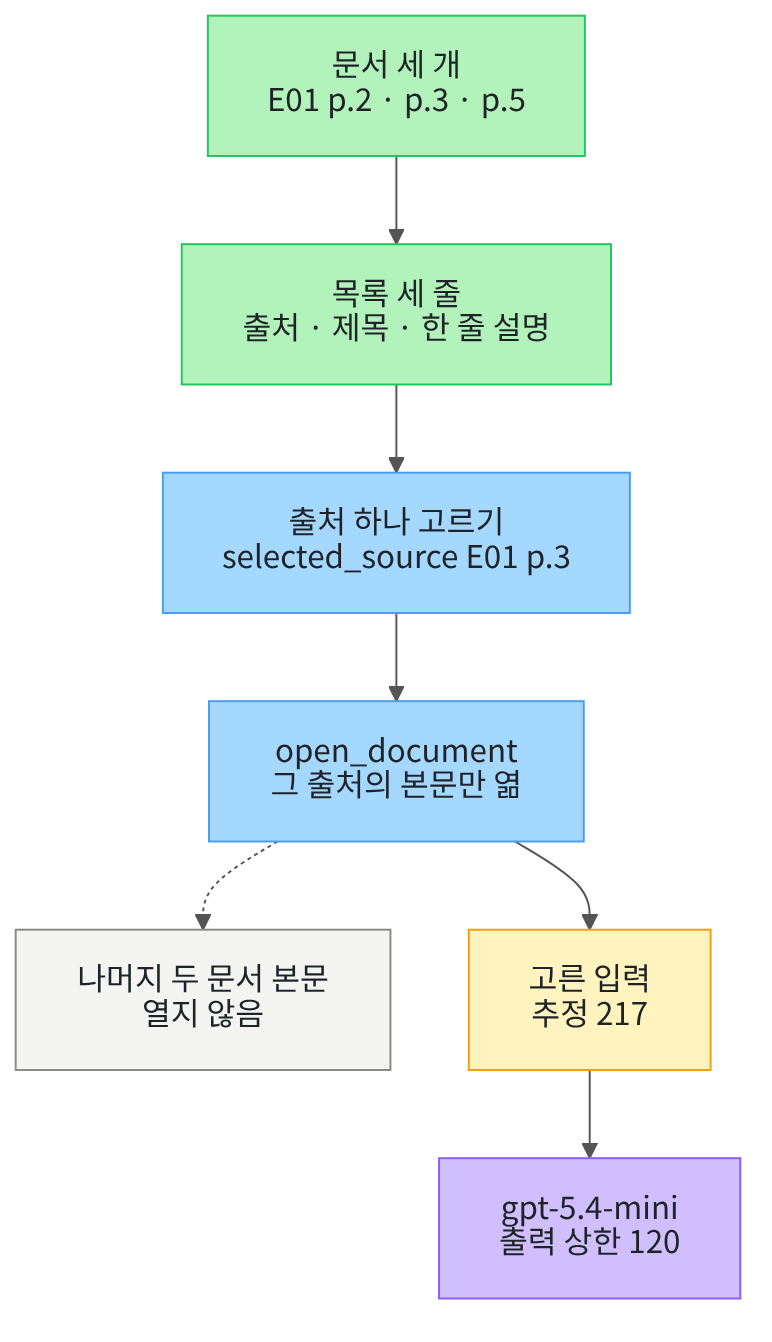

위에서 아래로 읽습니다. 맨 위 초록 상자 두 개는 문서 세 개와, 본문을 뺀 목록 세 줄입니다.
파란 상자 두 개는 사람이 출처 하나를 고르고, 함수가 그 출처의 본문만 여는 단계입니다.

회색 상자는 열지 않은 두 문서입니다. 노란 상자는 요청 전에 센 고른 입력의 추정 토큰 수이고, 보라 상자는 모델입니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01~05절과 같은 패키지 판을 씁니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3" "tiktoken==0.14.0"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("tiktoken:", version("tiktoken"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.8.0
tiktoken: 0.14.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `openai: 3.8.0`, `tiktoken: 0.14.0` 등 여섯 줄입니다.
준비물에 적은 기준 버전과 같습니다.

다섯 가지를 불러옵니다. 모듈 `hashlib`은 Ch 7 08절에서 파일 지문을 계산할 때 쓴 모듈입니다.
모듈 `json`과 `time`은 Ch 6 06절처럼 기록 파일을 쓰고, 실행 시각 글을 만들 때 씁니다.
나머지 두 줄은 토큰 수를 세는 라이브러리와 모델 객체를 만드는 함수입니다.

In [2]:
# 파일 지문·JSON 글·시각 글을 다루는 모듈, 토큰 수를 세는 라이브러리, 모델 함수를 불러옵니다
import hashlib
import json
import time

import tiktoken

from langchain.chat_models import init_chat_model

05절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


## 2. 05절에서 이어 쓰는 글과 함수

페르소나와 과업 명세는 02~05절과 글자까지 같습니다. 과업 명세는 문장마다 끝에 출처 표시를 적게 합니다.
출처 표시 `[E01 p.2]`는 모양을 보여 주는 예입니다.

In [4]:
# 02~05절과 같은 페르소나와 과업 명세를 만듭니다
persona_text = "당신은 미르시립도서관 안내 담당자입니다."
task_text = "주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 출처를 [E01 p.2]처럼 적으세요."
print("페르소나:", persona_text)
print("과업 명세:", task_text)

페르소나: 당신은 미르시립도서관 안내 담당자입니다.
과업 명세: 주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 출처를 [E01 p.2]처럼 적으세요.


**결과 읽기** — 두 줄은 `페르소나:`와 `과업 명세:`로 시작합니다. 과업 명세 줄에 `문장마다 끝에 출처를`이 있습니다.

수업 예산표도 01~05절과 같은 뺄셈 함수로 이어 씁니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [5]:
# 수업 예산에서 출력 예약분과 여유분을 빼, 입력에 쓸 수 있는 토큰 수를 반환하는 함수를 정의합니다
def input_budget(total_budget, output_reserve, safety_margin):
    available = total_budget - output_reserve - safety_margin
    return available

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

세 값을 01~05절과 같게 담고 입력 가용분을 구합니다.
실행 전에 예상합니다. 01~05절처럼 440일 것입니다.

In [6]:
# 01~05절과 같은 수업 예산·출력 예약분·여유분으로 입력 가용분을 계산합니다
total_budget = 600
output_reserve = 120
safety_margin = 40
available = input_budget(total_budget, output_reserve, safety_margin)
print("수업 예산:", total_budget)
print("출력 예약분:", output_reserve)
print("여유분:", safety_margin)
print("입력 가용분:", available)

수업 예산: 600
출력 예약분: 120
여유분: 40
입력 가용분: 440


**결과 읽기** — 네 줄은 `수업 예산: 600`, `출력 예약분: 120`, `여유분: 40`, `입력 가용분: 440`입니다.
05절 측정 입력은 이 입력 가용분을 일부러 넘겼습니다. 이 절의 세 입력 설계는 다시 이 예산표와 비교합니다.

요청 전에 토큰 수를 셀 함수도 01~05절과 같은 코드로 정의합니다.
함수 `count_tokens()`는 규칙 객체 `encoding`을 읽어 글 하나의 토큰 수를 반환합니다. 이 셀은 출력이 없습니다.

In [7]:
# 01~05절처럼 모델의 토큰화 규칙을 불러오고, 글 하나의 토큰 수를 반환하는 함수를 정의합니다
encoding = tiktoken.encoding_for_model("gpt-5.4-mini")


def count_tokens(text):
    token_ids = encoding.encode(text)
    return len(token_ids)

**결과 읽기** — 규칙 객체를 만들고 함수를 정의만 하는 셀이라 출력이 없습니다.

모델 객체는 02~05절처럼 출력 예약분을 출력 상한(`max_tokens`)으로 주어 만듭니다. 이 셀은 요청을 보내지 않습니다.

In [8]:
# 출력 예약분을 출력 상한으로 준 모델을 준비합니다(02~05절과 같은 설정)
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
    max_tokens=output_reserve,
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)
print("출력 상한(max_tokens):", model.max_tokens)
assert model.max_tokens == output_reserve

모델 이름: gpt-5.4-mini
temperature: 0.0
출력 상한(max_tokens): 120


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`, `temperature: 0.0`, `출력 상한(max_tokens): 120`입니다. `assert`도 통과했습니다.
이 노트북의 출력은 2026-09-17에 이 모델로 실행한 결과입니다. 실행마다 답 문장이 달라질 수 있습니다.
Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

03절 함수 `find_missing_words()`를 같은 코드로 정의합니다. 글 하나와 말 목록을 받아, 글에 없는 말만 목록으로 반환합니다.
이 셀은 정의만 하므로 출력이 없습니다.

In [9]:
# 글에 들어 있지 않은 지킬 말만 모아 반환하는 함수를 정의합니다(03절과 같은 코드)
def find_missing_words(text, words):
    missing = []
    for word in words:
        if word not in text:
            missing.append(word)
    return missing

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

04절 함수 `build_notes_messages()`를 같은 코드로 정의합니다. 기록 목록과 질문으로 Ch 7 모양의 메시지 목록을 만듭니다.
user 글은 기록마다 출처 표시를 붙인 줄, 빈 줄, 질문 순서입니다.
이 절에서는 기록 대신 문서 본문이나 목록 줄을 넣어도 같은 모양으로 이어 붙입니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [10]:
# 기록 목록과 질문 하나로 Ch 7 모양의 메시지 목록을 만들어 반환하는 함수를 정의합니다(04절과 같은 코드)
def build_notes_messages(notes, question):
    evidence_text = ""
    for note in notes:
        evidence_text = evidence_text + "[" + note["출처"] + "] " + note["내용"] + "\n"
    user_text = evidence_text + "\n" + "질문: " + question
    messages = [
        ("system", persona_text),
        ("developer", task_text),
        ("user", user_text),
    ]
    return messages

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

Ch 7 08절 함수 `estimate_openai_cost()`도 05절과 같은 코드로 정의합니다. 사용량 딕셔너리를 받아 요청 한 번의 예상 비용(달러)을 반환합니다.
기본값은 Ch 6 06절에서 확인한 mini 요금입니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [11]:
# 사용량과 세 요금(기본값 mini 요금)으로 요청 한 번의 예상 비용(달러)을 계산하는 함수를 정의합니다(Ch 7 08절·05절과 같은 코드)
def estimate_openai_cost(usage, input_rate=0.75, cached_input_rate=0.075, output_rate=4.50):
    if usage is None:
        return None
    # 캐시 입력 키가 없으면 할인 없이 모두 입력 요금으로 계산합니다
    details = usage.get("input_token_details", {})
    cache_read = details.get("cache_read", 0)
    normal_input = usage["input_tokens"] - cache_read
    input_cost = normal_input * input_rate + cache_read * cached_input_rate
    output_cost = usage["output_tokens"] * output_rate
    price_unit = 1000000
    return (input_cost + output_cost) / price_unit

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

## 3. Ch 7 기록 파일 읽기

Ch 7 08절은 과업 명세 세 버전의 기록을 JSON 파일 하나에 저장했습니다. 이 절은 그 파일을 읽고 지문을 계산해, 6절 기록 파일의 출처로 적습니다.

먼저 이 실습 폴더의 경로를 고릅니다. 노트북을 어느 폴더에서 열었는지에 따라 같은 폴더도 다른 경로로 보입니다.
후보는 프로젝트 맨 위에서 본 긴 경로, `notebooks` 폴더에서 본 한 칸 위 `..`, 실습 폴더 맨 위에서 본 `.`입니다.
후보 폴더 안에 `runs` 폴더와 `notebooks` 폴더가 모두 있으면 그 후보를 고르고 `break`로 반복을 멈춥니다.

실행 전에 예상합니다. 교재 출력은 프로젝트 맨 위에서 실행했으므로 긴 경로가 나올 것입니다.

In [12]:
# 작업 폴더에서 본 이 실습 폴더의 경로를 후보 세 개 가운데에서 고릅니다
lab_folder = None
for candidate in ["labs/part2/ch08-context-engineering", "..", "."]:
    has_runs = os.path.exists(candidate + "/runs")
    has_notebooks = os.path.exists(candidate + "/notebooks")
    if has_runs and has_notebooks:
        lab_folder = candidate
        break
print("실습 폴더를 찾았는가:", lab_folder is not None)
print("고른 경로:", lab_folder)
assert lab_folder is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

실습 폴더를 찾았는가: True
고른 경로: labs/part2/ch08-context-engineering


**결과 읽기** — 출력 줄은 `실습 폴더를 찾았는가: True`와 `고른 경로: labs/part2/ch08-context-engineering`입니다. `assert`도 통과했습니다.
`notebooks` 폴더에서 열면 고른 경로가 `..`로, 실습 폴더 맨 위에서 열면 `.`로 나옵니다.

Ch 7 08절 기록 파일은 이 실습 폴더와 나란히 있는 `ch07-prompt-engineering` 폴더의 `runs` 안에 있습니다.
그래서 고른 경로 뒤에 `/../`를 붙여 한 칸 올라간 뒤 그 폴더로 들어갑니다.
이름 `ch07_relative`에는 프로젝트 맨 위에서 본 경로를 따로 담습니다. 6절에서 기록 파일에 출처로 적을 경로입니다.

파일을 읽어 최상위 키, 실행 이름, 요금 확인 날짜, mini 요금, 버전 수를 출력합니다. 읽는 방법은 Ch 7 08절과 같은 `with open` + `json.loads(file.read())`입니다.
실행 전에 예상합니다. 최상위 키는 여섯 개이고, 버전 수는 3일 것입니다.

In [13]:
# Ch 7 08절 기록 파일을 읽어 최상위 키·실행 이름·요금 확인 날짜·mini 요금·버전 수를 확인합니다
ch07_relative = "labs/part2/ch07-prompt-engineering/runs/prompt-ab-continuity.json"
ch07_path = lab_folder + "/../ch07-prompt-engineering/runs/prompt-ab-continuity.json"
assert os.path.exists(ch07_path), "Ch 7 08절 노트북을 먼저 실행해 기록 파일을 만들어 주세요."
with open(ch07_path, encoding="utf-8") as file:
    ch07_record = json.loads(file.read())
ch07_keys = list(ch07_record.keys())
ch07_prices = ch07_record["settings"]["pricing_usd_per_million"]
print("최상위 키:", ch07_keys)
print("Ch 7 실행 이름:", ch07_record["run_id"])
print("요금 확인 날짜:", ch07_record["settings"]["pricing_date"])
print("mini 요금:", ch07_prices)
print("버전 수:", len(ch07_record["versions"]))
assert ch07_prices == {"ordinary_input": 0.75, "cached_input": 0.075, "output": 4.50}

최상위 키: ['run_id', 'run_date', 'source_chapter', 'source_record', 'settings', 'versions']
Ch 7 실행 이름: ch07-prompt-ab-20260917T070701
요금 확인 날짜: 2026-09-17
mini 요금: {'ordinary_input': 0.75, 'cached_input': 0.075, 'output': 4.5}
버전 수: 3


**결과 읽기** — 첫 줄은 `최상위 키: ['run_id', 'run_date', 'source_chapter', 'source_record', 'settings', 'versions']`입니다.
둘째·셋째 줄은 `Ch 7 실행 이름: ch07-prompt-ab-20260917T070701`과 `요금 확인 날짜: 2026-09-17`입니다.
넷째·다섯째 줄은 `mini 요금: {'ordinary_input': 0.75, 'cached_input': 0.075, 'output': 4.5}`과 `버전 수: 3`이고, `assert`도 통과했습니다.

실행 이름 끝의 숫자는 Ch 7 08절을 실행한 시각입니다. 그 노트북을 다시 실행했다면 다른 시각이 보입니다.
키 `versions`의 버전 기록은 이 절에서 읽지 않습니다. Ch 7 질문은 고객 문의라, 도서관 질문과 토큰 수를 비교하지 않기 때문입니다.

다음으로 Ch 7 08절에서 배운 파일 지문(SHA-256)을 계산합니다. 파일 바이트 전체로 계산해, 한 글자만 달라도 다른 글이 되는 값입니다.
모드 `"rb"`로 파일을 바이트 그대로 읽고, 함수 `hashlib.sha256()`과 메서드 `hexdigest()`로 64글자 글을 만듭니다.
실행 전에 예상합니다. 지문 글자 수는 64일 것입니다.

In [14]:
# Ch 7 기록 파일을 바이트 그대로 읽어 SHA-256 지문을 계산합니다(Ch 7 08절과 같은 방법)
with open(ch07_path, "rb") as file:
    ch07_bytes = file.read()
ch07_sha256 = hashlib.sha256(ch07_bytes).hexdigest()
print("지문 글자 수:", len(ch07_sha256))

지문 글자 수: 64


**결과 읽기** — 출력은 `지문 글자 수: 64` 한 줄입니다.
지문 글자는 Ch 7 08절 노트북을 다시 실행하면 바뀌므로 출력하지 않았습니다. 6절에서 이 지문을 기록 파일의 출처로 적습니다.

## 4. 목록을 먼저 보고 본문 열기

단계적 공개(progressive disclosure)는 자세한 내용을 필요한 단계에서 보여 주는 방법입니다.
도서관에서 목록 카드로 책을 고른 뒤, 그 책만 서가에서 꺼내 읽는 것과 비슷합니다.
이 절에서는 문서 목록을 먼저 보고, 질문에 필요한 문서 하나의 본문만 메시지 목록에 넣습니다.

먼저 E01 문서의 세 쪽에서 항목 하나씩 원문을 옮겨 적습니다. 자료 대출은 03절 원문에서 제목 줄을 뺀 글입니다.
이용 시간은 01절 근거 문단의 본문이고, 찾아오시는 길은 5쪽 원문입니다. 제목과 출처 표시는 다음 셀에서 따로 붙입니다.

In [15]:
# E01 문서 2·3·5쪽에서 항목 하나씩 본문을 옮겨 적고, 본문마다 토큰 수를 셉니다
hours_text = "평일(화~금) 이용 시간은 오전 9시부터 오후 10시까지입니다. 토요일과 일요일은 오전 9시부터 오후 6시까지 문을 엽니다.\n"
hours_text = hours_text + "매주 월요일은 정기 휴관일입니다. 법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 그 다음 날인 화요일에도 휴관합니다."
loan_text = "회원 한 사람이 한 번에 빌릴 수 있는 자료는 도서 7권과 영상 자료 2점입니다. 대출 기간은 도서 14일, 영상 자료 7일입니다.\n"
loan_text = loan_text + "대출 기간은 다른 이용자의 예약이 없는 경우 1회에 한해 7일 연장할 수 있습니다. "
loan_text = loan_text + "연장은 반납 예정일 전에 앱, 홈페이지, 전화(032-000-1998)로 신청합니다.\n"
loan_text = loan_text + "정기간행물 최신호, 참고도서(사전·연감), 향토자료는 관내에서만 열람할 수 있고 대출되지 않습니다."
way_text = "주소는 미르시 중앙동 도서관로 12입니다. 지하철 미르선 중앙역 3번 출구에서 걸어서 5분이며, 시내버스 12·34·56번이 도서관 앞에 정차합니다.\n"
way_text = way_text + "주차장은 80면이며 회원은 최초 2시간 무료, 이후 30분마다 500원입니다. 장애인 주차 구역 5면과 전기차 충전기 2기가 있습니다."
print("본문 토큰 수(이용 시간·자료 대출·찾아오시는 길):", count_tokens(hours_text), count_tokens(loan_text), count_tokens(way_text))

본문 토큰 수(이용 시간·자료 대출·찾아오시는 길): 88 128 103


**결과 읽기** — 출력 줄은 `본문 토큰 수(이용 시간·자료 대출·찾아오시는 길): 88 128 103`입니다.
세 본문을 모두 넣으면 본문만으로 300토큰이 넘습니다.

세 본문에 출처·제목·한 줄 설명을 붙여 문서 세 개를 만듭니다. 한 줄 설명은 02절 기록 파일의 한 문장 기록과 같은 글입니다.
그다음 본문을 뺀 목록을 만듭니다. 목록 한 줄은 출처 표시, 제목, 한 줄 설명입니다.

목록 줄도 04절 함수에 넣을 수 있게 키 `출처`와 `내용`으로 담습니다. 키 `내용`에는 제목과 설명을 이은 글이 들어갑니다.
실행 전에 예상합니다. 목록은 세 줄이고, 줄마다 본문보다 훨씬 짧을 것입니다.

In [16]:
# 문서 세 개에 출처·제목·한 줄 설명·본문을 붙이고, 본문을 뺀 목록을 만듭니다
documents = [
    {"출처": "E01 p.2", "제목": "2. 이용 시간", "설명": "매주 월요일은 정기 휴관일입니다.", "내용": hours_text},
    {"출처": "E01 p.3", "제목": "4. 자료 대출", "설명": "도서는 7권까지 14일 동안 대출할 수 있습니다.", "내용": loan_text},
    {"출처": "E01 p.5", "제목": "12. 찾아오시는 길", "설명": "회원은 최초 2시간 무료입니다.", "내용": way_text},
]
catalog = []
for document in documents:
    line_text = document["제목"] + ": " + document["설명"]
    catalog.append({"출처": document["출처"], "내용": line_text})
print("목록:")
for item in catalog:
    print("[" + item["출처"] + "] " + item["내용"])

목록:
[E01 p.2] 2. 이용 시간: 매주 월요일은 정기 휴관일입니다.
[E01 p.3] 4. 자료 대출: 도서는 7권까지 14일 동안 대출할 수 있습니다.
[E01 p.5] 12. 찾아오시는 길: 회원은 최초 2시간 무료입니다.


**결과 읽기** — 라벨 줄 `목록:` 아래 세 줄이 목록입니다. 둘째 줄은 `[E01 p.3] 4. 자료 대출: 도서는 7권까지 14일 동안 대출할 수 있습니다.`입니다.
셋째 줄 `[E01 p.5] 12. 찾아오시는 길: 회원은 최초 2시간 무료입니다.`의 설명은 02절 주차 기록과 같은 글입니다.

질문과 지킬 말은 03절과 글자까지 같습니다. 질문은 빌린 도서의 대출 기간을 연장할 수 있는지 묻습니다.
답에서 확인할 말은 지킬 말 가운데 연장 조건 세 개로 따로 적습니다. 권수와 기간은 연장 질문의 답에 꼭 들어가야 하는 말이 아니기 때문입니다.

In [17]:
# 03절과 같은 대출 연장 질문과 지킬 말을 만들고, 답에서 확인할 연장 조건 세 개를 따로 적습니다
loan_question = "미르시립도서관에서 빌린 도서의 대출 기간을 연장할 수 있나요?"
keep_words = ["7권", "14일", "예약이 없는 경우", "1회", "7일 연장"]
condition_words = ["예약이 없는 경우", "1회", "7일 연장"]
print("질문:", loan_question)
print("지킬 말:", keep_words)
print("답에서 확인할 연장 조건:", condition_words)

질문: 미르시립도서관에서 빌린 도서의 대출 기간을 연장할 수 있나요?
지킬 말: ['7권', '14일', '예약이 없는 경우', '1회', '7일 연장']
답에서 확인할 연장 조건: ['예약이 없는 경우', '1회', '7일 연장']


**결과 읽기** — 출력 줄은 `질문:` 줄, `지킬 말: ['7권', '14일', '예약이 없는 경우', '1회', '7일 연장']`, `답에서 확인할 연장 조건: ['예약이 없는 경우', '1회', '7일 연장']`입니다.

목록에서 출처로 문서를 찾아 반환하는 함수를 정의합니다. 함수 `open_document()`는 문서 목록과 출처 글을 받습니다.
반복문이 출처가 같은 문서를 만나면 `return`으로 그 문서를 반환합니다. 반복이 끝날 때까지 없으면 `None`을 반환합니다.

함수 안의 `return`은 반복문 안에 있어도 그 자리에서 함수를 끝냅니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [18]:
# 문서 목록과 출처 글을 받아, 출처가 같은 문서를 찾아 반환하는 함수를 정의합니다(없으면 None)
def open_document(document_list, source):
    for document in document_list:
        if document["출처"] == source:
            return document
    return None

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

목록을 읽고 사람이 출처 하나를 고릅니다. 질문이 대출 연장이므로 목록 둘째 줄 「4. 자료 대출」의 출처를 고릅니다.
고른 출처로 본문을 열고, 본문과 목록 줄에서 빠진 지킬 말을 비교합니다. 이 단계에서 모델은 문서를 고르지 않습니다.

실행 전에 예상합니다. 본문에는 지킬 말이 모두 있고, 목록 줄에는 연장 조건이 빠졌을 것입니다.

In [19]:
# 목록을 보고 고른 출처 하나로 본문을 열고, 본문과 목록 줄에서 빠진 지킬 말을 비교합니다
selected_source = "E01 p.3"
selected_document = open_document(documents, selected_source)
catalog_line = open_document(catalog, selected_source)
print("고른 출처:", selected_source)
print("연 문서 제목:", selected_document["제목"])
print("연 본문에서 빠진 지킬 말:", find_missing_words(selected_document["내용"], keep_words))
print("목록 줄에서 빠진 지킬 말:", find_missing_words(catalog_line["내용"], keep_words))

고른 출처: E01 p.3
연 문서 제목: 4. 자료 대출
연 본문에서 빠진 지킬 말: []
목록 줄에서 빠진 지킬 말: ['예약이 없는 경우', '1회', '7일 연장']


**결과 읽기** — 출력 줄은 `고른 출처: E01 p.3`, `연 문서 제목: 4. 자료 대출`, `연 본문에서 빠진 지킬 말: []`입니다.
마지막 줄은 `목록 줄에서 빠진 지킬 말: ['예약이 없는 경우', '1회', '7일 연장']`입니다.

목록 줄에는 권수와 기간만 있고 연장 조건이 없습니다. 목록은 어느 본문을 열지 고르는 데 쓰는 짧은 글이고, 답의 근거를 대신하지 않습니다.
02절에서는 기록에 없는 조건을 출처로 원문에서 확인한다고 했습니다. 이 절은 그 확인을 본문 열기로 합니다.

함수 `open_document()`는 목록 줄에도 쓸 수 있습니다. 목록 줄에도 키 `출처`가 있기 때문입니다.

## 5. 세 입력 설계를 같은 질문으로 보내기

입력 설계는 이번 요청의 메시지 목록에 무엇을 넣을지 정한 방식입니다. 세 설계를 비교합니다.

- 전체 입력(full): 목록의 문서 세 개 본문을 모두 넣습니다.
- 고른 입력(selected): 4절에서 연 본문 하나만 넣습니다.
- 줄인 입력(compressed): 03절에서 사람이 원문을 읽고 줄인 대출 기록을 넣습니다.

질문·페르소나·과업 명세·모델 설정은 세 요청이 같습니다. 먼저 요청 전에 세 목록의 추정 입력을 셉니다.
실행 전에 예상합니다. 추정 입력은 전체, 고른, 줄인 입력 순서로 작아질 것입니다.

In [20]:
# 세 입력 설계의 메시지 목록을 만들고, 요청 전에 추정 입력을 셉니다(요청은 보내지 않습니다)
loan_note = {"출처": "E01 p.3", "기관": "미르시립도서관", "주제": "대출", "내용": "회원 한 사람의 도서 대출 기준은 7권·14일이며, 다른 이용자의 예약이 없는 경우에만 1회 7일 연장할 수 있습니다."}
full_messages = build_notes_messages(documents, loan_question)
selected_messages = build_notes_messages([selected_document], loan_question)
compressed_messages = build_notes_messages([loan_note], loan_question)
shared_tokens = count_tokens(persona_text) + count_tokens(task_text)
full_estimate = shared_tokens + count_tokens(full_messages[2][1])
selected_estimate = shared_tokens + count_tokens(selected_messages[2][1])
compressed_estimate = shared_tokens + count_tokens(compressed_messages[2][1])
print("추정 입력 합계(전체·고른·줄인):", full_estimate, selected_estimate, compressed_estimate)
print("입력 가용분 안에 드는가:", full_estimate <= available, selected_estimate <= available, compressed_estimate <= available)

추정 입력 합계(전체·고른·줄인): 420 217 128
입력 가용분 안에 드는가: True True True


**결과 읽기** — 출력 줄은 `추정 입력 합계(전체·고른·줄인): 420 217 128`과 `입력 가용분 안에 드는가: True True True`입니다.

세 목록 모두 01절 입력 가용분 440 안에 듭니다. 전체 입력 420은 고른 입력 217의 두 배쯤이고, 가용분까지 20토큰이 남습니다.
줄인 입력 128은 03절 대출 목록의 추정 입력과 같은 값입니다. 같은 줄인 기록과 질문으로 만든 목록이기 때문입니다.

요청 한 번의 결과를 기록 한 줄로 만드는 함수를 정의합니다. 함수 `make_design_record()`는 설계 이름과 응답 객체를 받습니다.
기록 키는 `설계`, `답`, `입력 토큰 수`, `캐시 입력 토큰 수`, `출력 토큰 수`, `끝난 이유`, `예상 비용(달러)`, `답에서 빠진 연장 조건`입니다.
이 셀은 정의만 하므로 출력이 없습니다.

In [21]:
# 설계 이름과 응답 객체로, 토큰 수·끝난 이유·예상 비용·답에서 빠진 연장 조건을 담은 기록 한 줄을 반환하는 함수를 정의합니다
def make_design_record(design_name, run_response):
    run_usage = run_response.usage_metadata
    run_cost = estimate_openai_cost(run_usage)
    record = {"설계": design_name, "답": run_response.text}
    record["입력 토큰 수"] = run_usage["input_tokens"]
    record["캐시 입력 토큰 수"] = run_usage["input_token_details"]["cache_read"]
    record["출력 토큰 수"] = run_usage["output_tokens"]
    record["끝난 이유"] = run_response.response_metadata["finish_reason"]
    record["예상 비용(달러)"] = round(run_cost, 6)
    record["답에서 빠진 연장 조건"] = find_missing_words(run_response.text, condition_words)
    return record

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

전체 입력부터 보냅니다. 요청은 셀마다 하나씩, 세 셀로 나눠 보냅니다.
이 목록에는 대출 질문에 필요 없는 이용 시간·찾아오시는 길 본문도 들어 있습니다. 04절 컨텍스트 혼란 조건과 같은 모양입니다.

실행 전에 예상해 봅니다. 자료 대출 본문이 들어 있으니 연장 조건 세 개가 답에 나올 것입니다.

In [22]:
# 전체 입력(full) 목록을 보내고 기록 한 줄을 만듭니다(요청 1번)
full_response = model.invoke(full_messages)
print("답:")
print(full_response.text)
full_record = make_design_record("전체 입력", full_response)
print("끝난 이유:", full_record["끝난 이유"])
print("입력 토큰 수:", full_record["입력 토큰 수"])
print("출력 토큰 수:", full_record["출력 토큰 수"])
print("답에서 빠진 연장 조건:", full_record["답에서 빠진 연장 조건"])

답:
네, 다른 이용자의 예약이 없는 경우에 한해 1회 7일 연장할 수 있으며, 반납 예정일 전에 앱·홈페이지·전화(032-000-1998)로 신청합니다. [E01 p.3]
끝난 이유: stop
입력 토큰 수: 434
출력 토큰 수: 57
답에서 빠진 연장 조건: []


**결과 읽기** — 라벨 줄 `답:` 아래 답은 한 문장이고, 첫머리는 `네, 다른 이용자의 예약이 없는 경우에 한해 1회 7일 연장할 수 있으며,`입니다.
신청 방법까지 적은 뒤 끝에 `[E01 p.3]`을 붙였습니다.
그 아래 줄은 `끝난 이유: stop`, `입력 토큰 수: 434`, `출력 토큰 수: 57`, `답에서 빠진 연장 조건: []`입니다.

연장 조건 세 개가 모두 답에 있고, 이용 시간·찾아오시는 길 본문의 내용은 이번 답에 없었습니다.
04절 혼란 조건처럼 필요 없는 본문을 넣었지만, 이번 답에서는 그 내용을 쓴 곳을 찾지 못했습니다. 실행마다 답 문장이 달라질 수 있습니다.

고른 입력을 보냅니다. 추정 입력은 전체 입력의 절반쯤입니다.
실행 전에 예상해 봅니다. 같은 자료 대출 본문이 들어 있으니, 연장 조건은 전체 입력의 답처럼 모두 나올 것입니다.

In [23]:
# 고른 입력(selected) 목록을 보내고 기록 한 줄을 만듭니다(요청 1번)
selected_response = model.invoke(selected_messages)
print("답:")
print(selected_response.text)
selected_record = make_design_record("고른 입력", selected_response)
print("끝난 이유:", selected_record["끝난 이유"])
print("입력 토큰 수:", selected_record["입력 토큰 수"])
print("출력 토큰 수:", selected_record["출력 토큰 수"])
print("답에서 빠진 연장 조건:", selected_record["답에서 빠진 연장 조건"])

답:
네, 대출 기간은 다른 이용자의 예약이 없는 경우 1회에 한해 7일 연장할 수 있으며, 반납 예정일 전에 앱·홈페이지·전화(032-000-1998)로 신청합니다. [E01 p.3]  
다만 정기간행물 최신호, 참고도서(사전·연감), 향토자료는 관내 열람만 가능하고 대출되지 않습니다. [E01 p.3]
끝난 이유: stop
입력 토큰 수: 231
출력 토큰 수: 104
답에서 빠진 연장 조건: []


**결과 읽기** — 라벨 줄 `답:` 아래 답은 두 문장입니다. 첫 문장은 `네, 대출 기간은 다른 이용자의 예약이 없는 경우 1회에 한해 7일 연장할 수 있으며,`로 시작합니다.
둘째 문장은 `다만 정기간행물 최신호, 참고도서(사전·연감), 향토자료는 관내 열람만 가능하고 대출되지 않습니다.`입니다.
그 아래 줄은 `끝난 이유: stop`, `입력 토큰 수: 231`, `출력 토큰 수: 104`, `답에서 빠진 연장 조건: []`입니다.

입력은 전체 입력 434보다 203토큰 적었지만, 출력은 57에서 104로 늘었습니다. 둘째 문장은 연장 질문에 필요하지 않은 대출 제외 자료 이야기입니다.
이 문장도 자료 대출 본문에 있는 글이라, 넣은 근거 밖의 말은 아닙니다. 왜 이번 답에 둘째 문장이 붙었는지는 이 실행으로 알 수 없습니다.

줄인 입력을 보냅니다. 03절 줄인 기록 한 문장에 권수·기간과 연장 조건이 함께 들어 있습니다.
실행 전에 예상해 봅니다. 연장 조건 세 개가 모두 답에 나올 것입니다.

In [24]:
# 줄인 입력(compressed) 목록을 보내고 기록 한 줄을 만듭니다(요청 1번)
compressed_response = model.invoke(compressed_messages)
print("답:")
print(compressed_response.text)
compressed_record = make_design_record("줄인 입력", compressed_response)
print("끝난 이유:", compressed_record["끝난 이유"])
print("입력 토큰 수:", compressed_record["입력 토큰 수"])
print("출력 토큰 수:", compressed_record["출력 토큰 수"])
print("답에서 빠진 연장 조건:", compressed_record["답에서 빠진 연장 조건"])

답:
네, 다른 이용자의 예약이 없는 경우에 한해 1회 7일 연장할 수 있습니다. [E01 p.3] 대출 기준은 7권·14일입니다. [E01 p.3]
끝난 이유: stop
입력 토큰 수: 142
출력 토큰 수: 53
답에서 빠진 연장 조건: []


**결과 읽기** — 라벨 줄 `답:` 아래 답은 두 문장이고, 문장마다 끝에 `[E01 p.3]`이 붙었습니다. 둘째 문장은 `대출 기준은 7권·14일입니다.`입니다.
그 아래 줄은 `끝난 이유: stop`, `입력 토큰 수: 142`, `출력 토큰 수: 53`, `답에서 빠진 연장 조건: []`입니다.

줄인 입력의 답에도 연장 조건 세 개가 모두 들어갔습니다. 03절에서 연장 조건을 남기며 줄인 기록을 넣은 목록입니다.
줄인 기록에 있던 권수·기간은 답의 둘째 문장이 됐습니다. 원문에 있던 신청 방법은 줄인 기록에 없고, 이번 답에도 없었습니다.

세 기록을 한 표로 모읍니다. 반복문은 이미 받은 기록을 출력만 하고, 요청을 보내지 않습니다.
마지막 줄은 세 요청의 예상 비용 합계입니다.

In [25]:
# 세 기록을 한 줄에 한 요청씩 출력하고, 예상 비용 합계를 구합니다
design_records = [full_record, selected_record, compressed_record]
total_cost = 0
print("기록표(설계 | 입력 토큰 수 | 캐시 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 답에서 빠진 연장 조건 | 예상 비용(달러)):")
for record in design_records:
    total_cost = total_cost + record["예상 비용(달러)"]
    print(record["설계"], "|", record["입력 토큰 수"], "|", record["캐시 입력 토큰 수"], "|", record["출력 토큰 수"], "|", record["끝난 이유"], "|", record["답에서 빠진 연장 조건"], "|", record["예상 비용(달러)"])
print("세 요청 예상 비용 합계(달러):", round(total_cost, 6))

기록표(설계 | 입력 토큰 수 | 캐시 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 답에서 빠진 연장 조건 | 예상 비용(달러)):
전체 입력 | 434 | 0 | 57 | stop | [] | 0.000582
고른 입력 | 231 | 0 | 104 | stop | [] | 0.000641
줄인 입력 | 142 | 0 | 53 | stop | [] | 0.000345
세 요청 예상 비용 합계(달러): 0.001568


**결과 읽기** — 라벨 줄 아래 세 줄은 `전체 입력 | 434 | 0 | 57 | stop | [] | 0.000582`, `고른 입력 | 231 | 0 | 104 | stop | [] | 0.000641`, `줄인 입력 | 142 | 0 | 53 | stop | [] | 0.000345`입니다.
마지막 줄은 `세 요청 예상 비용 합계(달러): 0.001568`입니다.

입력 토큰 수는 전체, 고른, 줄인 입력 순으로 작았고, 세 목록 모두 실제 입력이 추정보다 14 많았습니다.
예상 비용은 고른 입력이 전체 입력보다 컸습니다. 출력 요금이 입력 요금의 6배라, 출력 47토큰이 늘어난 요금이 입력 203토큰이 줄어든 요금보다 컸습니다.
세 답 모두 연장 조건은 빠지지 않았고, 캐시 입력은 0이었습니다. 설계마다 한 번 보낸 결과라, 이 비용 차이를 설계의 순위로 쓰지 않습니다.

## 6. 기록 파일로 남기기

세 설계 기록을 JSON 파일 하나에 저장합니다. Ch 7 08절 기록 파일과 같은 방법입니다.
최상위 키는 Ch 7 기록 파일처럼 영어로 둡니다. 두 파일을 같은 이름으로 읽을 수 있게 하려는 것입니다. 설계 기록의 키는 한국어 그대로입니다.

키 `source_record`에는 출처를 적습니다. 3절 경로 `ch07_relative`, 3절 지문, Ch 7 실행 이름입니다.
키 `settings`에는 모델 설정과 요금을, 키 `question`에는 질문을, 키 `results`에는 세 기록 목록을 담습니다.
실행 이름은 Ch 7 08절처럼 `ch08-context-`에 지금 시각을 이어 만듭니다.

실행 전에 예상합니다. 최상위 키는 일곱 개이고, 출처의 실행 이름은 3절 Ch 7 실행 이름과 같을 것입니다.

In [26]:
# 실행 이름·출처·고정 조건·질문·세 설계 기록을 딕셔너리 하나에 모읍니다
run_stamp = time.strftime("%Y%m%dT%H%M%S")
source_record = {"path": ch07_relative, "sha256": ch07_sha256, "run_id": ch07_record["run_id"]}
settings = {"model": "openai:gpt-5.4-mini", "temperature": 0, "reasoning_effort": "none", "max_tokens": output_reserve,
            "pricing_date": ch07_record["settings"]["pricing_date"], "pricing_usd_per_million": ch07_prices}
run_record = {"run_id": "ch08-context-" + run_stamp, "run_date": time.strftime("%Y-%m-%d"), "source_chapter": "ch08",
              "source_record": source_record, "settings": settings, "question": loan_question, "results": design_records}
run_keys = list(run_record.keys())
print("실행 이름:", run_record["run_id"])
print("최상위 키:", run_keys)
print("출처의 Ch 7 실행 이름:", run_record["source_record"]["run_id"])

실행 이름: ch08-context-20260917T121654
최상위 키: ['run_id', 'run_date', 'source_chapter', 'source_record', 'settings', 'question', 'results']
출처의 Ch 7 실행 이름: ch07-prompt-ab-20260917T070701


**결과 읽기** — 첫 줄은 `실행 이름: ch08-context-`로 시작하고, 뒤에 이 셀을 실행한 시각이 붙습니다.
둘째 줄은 `최상위 키: ['run_id', 'run_date', 'source_chapter', 'source_record', 'settings', 'question', 'results']`입니다.
셋째 줄은 `출처의 Ch 7 실행 이름: ch07-prompt-ab-20260917T070701`로, 3절에서 읽은 이름과 같습니다.

파일은 3절에서 고른 실습 폴더 경로 아래 `runs` 폴더에 씁니다. 사본은 `runs/continuity` 아래에 실행 시각 이름의 폴더를 새로 만들어 씁니다.
기록 파일은 실행할 때마다 덮어쓰지만, 사본은 실행마다 남습니다.
함수 `os.makedirs()`는 이미 있는 폴더면 오류를 내므로 앞선 사본을 덮어쓰지 않습니다. 파일 쓰기는 Ch 7 08절과 같은 `json.dumps()` + `with open` 모양입니다.

실행 전에 예상합니다. 두 파일이 모두 있다는 `True` 두 줄이 나올 것입니다.

In [27]:
# runs 폴더에 기록 파일을 쓰고, 실행 시각 이름의 폴더를 새로 만들어 같은 내용의 사본도 씁니다
record_path = lab_folder + "/runs/context-design-continuity.json"
copy_folder = lab_folder + "/runs/continuity/" + run_stamp
os.makedirs(copy_folder)
copy_path = copy_folder + "/context-design-continuity.json"
payload = json.dumps(run_record, ensure_ascii=False, indent=2)
with open(record_path, "w", encoding="utf-8") as file:
    file.write(payload)
with open(copy_path, "w", encoding="utf-8") as file:
    file.write(payload)
print("기록 파일이 있는가:", os.path.exists(record_path))
print("사본이 있는가:", os.path.exists(copy_path))

기록 파일이 있는가: True
사본이 있는가: True


**결과 읽기** — 두 줄은 `기록 파일이 있는가: True`와 `사본이 있는가: True`입니다. 파일 경로는 작업 폴더마다 달라서 출력하지 않았습니다.
이 셀만 다시 실행하면 같은 실행 시각 폴더가 이미 있어 `os.makedirs()`에서 `FileExistsError`가 납니다.
6절 첫 셀부터 다시 실행하면 새 실행 이름으로 기록 파일을 덮어쓰고, 사본 폴더가 하나 더 생깁니다.

쓴 파일을 다시 읽어 확인합니다. 출처 지문이 3절 지문과 같은지, 설계 기록이 세 개인지 봅니다.
기록 파일과 사본도 바이트로 읽어 지문을 비교합니다. 지문이 같으면 두 파일의 내용이 같다고 봅니다.

실행 전에 예상합니다. 두 줄은 `True`이고, 설계 기록 수는 3일 것입니다.

In [28]:
# 쓴 기록 파일을 다시 읽어 출처 지문·설계 기록 수를 확인하고, 사본과 지문을 비교합니다
with open(record_path, encoding="utf-8") as file:
    saved = json.loads(file.read())
with open(record_path, "rb") as file:
    record_bytes = file.read()
with open(copy_path, "rb") as file:
    copy_bytes = file.read()
record_sha256 = hashlib.sha256(record_bytes).hexdigest()
copy_sha256 = hashlib.sha256(copy_bytes).hexdigest()
print("출처 지문이 Ch 7 파일 지문과 같은가:", saved["source_record"]["sha256"] == ch07_sha256)
print("설계 기록 수:", len(saved["results"]))
print("기록 파일과 사본의 지문이 같은가:", record_sha256 == copy_sha256)
assert saved["source_record"]["sha256"] == ch07_sha256 and record_sha256 == copy_sha256

출처 지문이 Ch 7 파일 지문과 같은가: True
설계 기록 수: 3
기록 파일과 사본의 지문이 같은가: True


**결과 읽기** — 세 줄은 `출처 지문이 Ch 7 파일 지문과 같은가: True`, `설계 기록 수: 3`, `기록 파일과 사본의 지문이 같은가: True`입니다. `assert`도 통과했습니다.

이제 이 절의 기록 파일은 Ch 7 기록 파일의 경로·지문·실행 이름을 출처로 품습니다. Ch 7 기록 파일은 Ch 6 기록 파일을 출처로 적었습니다.
앞 파일의 지문을 뒤 파일이 적어 두는 이 연결을 Ch 7 08절에서 기록 사슬이라고 불렀습니다.
Ch 7 08절 노트북을 다시 실행하면 그 파일의 지문이 바뀝니다. 그러면 이 파일의 출처와 맞지 않으므로 이 노트북도 다시 실행합니다.

## 7. 값 바꿔 보기 — 고른 출처 바꾸기

바꾸는 값은 4절에서 고른 출처 하나입니다. 목록 둘째 줄 대신 셋째 줄의 출처를 고르고 본문을 엽니다.
목록에 없는 출처를 넣으면 함수가 무엇을 반환하는지도 봅니다. 요청은 보내지 않습니다.

실행 전에 예상합니다. 찾아오시는 길 본문에는 지킬 말이 하나도 없을 것입니다.

In [29]:
# 고른 출처만 E01 p.5로 바꿔 본문을 열고, 빠진 지킬 말과 추정 입력을 봅니다(요청은 보내지 않습니다)
changed_source = "E01 p.5"
changed_document = open_document(documents, changed_source)
changed_messages = build_notes_messages([changed_document], loan_question)
changed_estimate = shared_tokens + count_tokens(changed_messages[2][1])
print("바꾼 출처:", changed_source)
print("연 문서 제목:", changed_document["제목"])
print("연 본문에서 빠진 지킬 말:", find_missing_words(changed_document["내용"], keep_words))
print("추정 입력 합계:", changed_estimate)
print("목록에 없는 출처로 연 결과:", open_document(documents, "E01 p.4"))

바꾼 출처: E01 p.5
연 문서 제목: 12. 찾아오시는 길
연 본문에서 빠진 지킬 말: ['7권', '14일', '예약이 없는 경우', '1회', '7일 연장']
추정 입력 합계: 192
목록에 없는 출처로 연 결과: None


**결과 읽기** — 출력 줄은 `바꾼 출처: E01 p.5`, `연 문서 제목: 12. 찾아오시는 길`, `추정 입력 합계: 192`입니다.
셋째 줄 `연 본문에서 빠진 지킬 말: ['7권', '14일', '예약이 없는 경우', '1회', '7일 연장']`에서 다섯 개가 모두 빠졌습니다.
마지막 줄은 `목록에 없는 출처로 연 결과: None`입니다.

추정 입력 192는 입력 가용분 안이라, 예산표로는 잘못 고른 것을 알 수 없습니다. 연 본문을 지킬 말로 검사해야 드러납니다.
출처를 잘못 고르면 짧고 싼 입력이어도 답에 필요한 조건이 처음부터 빠집니다.
목록에 없는 출처는 `None`이 나오므로, 본문을 쓰기 전에 확인합니다.

## 8. Before — 목록만 넣고 본문을 열지 않은 요청

Before에서는 4절 목록 세 줄만 user 글에 넣어 보냅니다. 목록을 본 뒤 본문을 여는 단계를 빼먹은 경우입니다.
질문·페르소나·과업 명세·출력 상한 120은 5절 세 요청과 같습니다.

실행 전에 예상해 봅니다. 목록 줄에는 연장 조건이 없으니, 답에서도 연장 조건이 빠질 것입니다.

In [30]:
# 목록 세 줄만 넣은 메시지 목록을 만들어 보내고 기록 한 줄을 만듭니다(요청 1번)
before_messages = build_notes_messages(catalog, loan_question)
before_estimate = shared_tokens + count_tokens(before_messages[2][1])
print("Before 추정 입력 합계:", before_estimate)
before_response = model.invoke(before_messages)
print("답:")
print(before_response.text)
before_record = make_design_record("목록만", before_response)
print("입력 토큰 수:", before_record["입력 토큰 수"])
print("출력 토큰 수:", before_record["출력 토큰 수"])
print("답에서 빠진 연장 조건:", before_record["답에서 빠진 연장 조건"])

Before 추정 입력 합계: 159


답:
주어진 근거에는 도서 대출 기간 연장 가능 여부에 대한 정보가 없습니다. 도서는 7권까지 14일 동안 대출할 수 있다고만 안내되어 있습니다. [E01 p.3]
입력 토큰 수: 173
출력 토큰 수: 50
답에서 빠진 연장 조건: ['예약이 없는 경우', '1회', '7일 연장']


**결과 읽기** — 첫 줄은 `Before 추정 입력 합계: 159`입니다. 라벨 줄 `답:` 아래 첫 문장은 `주어진 근거에는 도서 대출 기간 연장 가능 여부에 대한 정보가 없습니다.`입니다.
둘째 문장은 권수와 기간만 안내되어 있다고 말하고, 끝에 `[E01 p.3]`을 붙였습니다.
아래 줄은 `입력 토큰 수: 173`, `출력 토큰 수: 50`, `답에서 빠진 연장 조건: ['예약이 없는 경우', '1회', '7일 연장']`입니다.

목록 줄에 연장 조건이 없었고, 답에서도 연장 조건 세 개가 모두 빠졌습니다. 오류는 나지 않았고, 답은 목록 줄의 권수·기간만 되풀이했습니다.
연장할 수 있는지는 자료 대출 본문에 있습니다. 이번 요청은 답할 수 있는 질문인데도 답을 얻지 못한 채 끝났습니다.

과업 명세는 문장마다 출처를 적게 했지만, 첫 문장에는 출처 표시가 없었습니다. 실행마다 답 문장이 달라질 수 있습니다.

## 9. After — 고른 출처의 본문을 연 요청

After에서 고치는 곳은 목록 다음 단계 하나입니다. 목록에서 고른 출처의 본문을 열어, 목록 줄 대신 본문을 넣습니다.
이 목록은 5절 고른 입력과 같은 목록이어야 합니다. 셀에서 `==`로 확인한 뒤 보냅니다.

실행 전에 예상합니다. 답에 연장 조건 세 개가 들어갈 것입니다.

In [31]:
# 고른 출처의 본문을 연 목록이 5절 고른 입력과 같은지 확인하고, 보내서 기록 한 줄을 만듭니다(요청 1번)
after_document = open_document(documents, selected_source)
after_messages = build_notes_messages([after_document], loan_question)
print("5절 고른 입력과 같은 목록인가:", after_messages == selected_messages)
assert after_messages == selected_messages
after_response = model.invoke(after_messages)
print("답:")
print(after_response.text)
after_record = make_design_record("목록에서 고른 본문", after_response)
print("입력 토큰 수:", after_record["입력 토큰 수"])
print("출력 토큰 수:", after_record["출력 토큰 수"])
print("답에서 빠진 연장 조건:", after_record["답에서 빠진 연장 조건"])

5절 고른 입력과 같은 목록인가: True


답:
네, 다른 이용자의 예약이 없는 경우 도서 대출 기간은 1회에 한해 7일 연장할 수 있습니다. 연장은 반납 예정일 전에 앱, 홈페이지, 전화(032-000-1998)로 신청합니다. [E01 p.3]
입력 토큰 수: 231
출력 토큰 수: 64
답에서 빠진 연장 조건: []


**결과 읽기** — 첫 줄은 `5절 고른 입력과 같은 목록인가: True`이고, `assert`도 통과했습니다.
라벨 줄 `답:` 아래 첫 문장은 `네, 다른 이용자의 예약이 없는 경우 도서 대출 기간은 1회에 한해 7일 연장할 수 있습니다.`입니다.
둘째 문장은 신청 방법입니다. 아래 줄은 `입력 토큰 수: 231`, `출력 토큰 수: 64`, `답에서 빠진 연장 조건: []`입니다.

본문을 열자 연장 조건 세 개가 모두 답에 들어갔습니다. 질문·모델·과업 명세는 Before와 같고, user 글의 근거만 목록 줄에서 본문으로 바뀌었습니다.
이 목록은 5절 고른 입력과 같지만, 답은 5절 답과 달랐습니다. 5절 답은 대출되지 않는 자료 문장을 더해 출력 104토큰이었고, 이번 답은 64토큰이었습니다.
같은 목록을 temperature 0으로 보내도 답 문장과 출력 토큰 수는 달라질 수 있습니다.

## 정리

- 목록을 먼저 보고 고른 출처 하나의 본문만 열었습니다. 목록만 넣은 Before 답에는 연장 조건이 모두 빠졌고, 본문을 연 After 답에는 모두 들어갔습니다.
- 전체·고른·줄인 입력의 추정 입력은 420·217·128이었고, 세 답 모두 연장 조건이 빠지지 않았습니다. 이번 예상 비용은 출력이 가장 긴 고른 입력이 가장 컸습니다.
- 세 기록을 Ch 7 기록 파일의 지문과 함께 기록 파일에 남겨 기록 사슬을 이었습니다. 출처를 잘못 고르면 짧은 입력이어도 조건이 처음부터 빠집니다.

다음 학습인 Ch 9 01절은 같은 E01 문서를 PDF에서 쪽마다 읽습니다. 이 절에서 사람이 고르던 본문을 검색이 고르게 됩니다.